# Freeze the setup: locked test papers, final inputs, frozen config, baseline ladder

**Input:** `mstar_calibration.zip` (or its `features_with_folds.csv`) from the m* notebook run on the updated preprocessing.

| Step | What | Why (thesis) |
|---|---|---|
| **1** | Lock away ~18 % of papers as the **final test set** (hash-chosen, stratified by family) | one honest score at the very end; no decision may touch these papers |
| **2** | **Decide the inputs**, on development papers only: does the correction need s_SPB as an input, or is ln(n/N_c) enough? | a documented, data-backed input choice |
| **3** | **Freeze** data + every setting in `frozen_config.json` + `frozen_dataset.csv` | exact reproducibility; every later notebook reads from these |
| **4** | **Baseline ladder** on development papers: SPB → SPB + linear → SPB + quadratic → (SPB + PySR, next notebook) → XGBoost | the table PySR must beat |
| 5 *(optional)* | Prioritised family-review list | the compositions whose labels matter most, to check first |

Only |S| is modelled (the magnitude, not the sign). **Nothing in this notebook evaluates the test papers.**

## 0. Settings

In [28]:
INPUT = "features_with_folds.csv"      # or "mstar_calibration.zip"
OUT_DIR = "frozen_setup"
EXCLUDE_FAMILIES = ["Marcasite FeSb2"] # SPB not applicable
T_MIN = 100.0                          # K
TARGET = "additive"                    # Δs = s − s_SPB
TRAIN_EXCLUDE_BIPOLAR = True           # post-peak bipolar points removed from TRAINING only
REQUIRE_MOBILITY = True                # keep only rows with a QC-passed conductivity, so both input sets use identical rows
T_REF = 300.0
TEST_FRACTION = 0.18                   # share of papers locked away (per family stratum)
TEST_SALT = "seebeck-lockbox-v1"       # changing this changes the test papers: DON'T, once frozen
N_FOLDS = 5
SEEDS = [42, 7, 123, 2024, 31415]      # development folds are rebuilt on dev papers only, same method as before
MIN_TRAIN_PAPERS = 3
M_BOUNDS = (0.05, 20.0)
CANDIDATE_SETS = {                      # step 2 decides between the pairs
    "Hall-only | s_SPB input":            ["s_SPB", "ln_n_Nc", "tau"],
    "Hall-only | no s_SPB input":         ["ln_n_Nc", "tau"],
    "Hall + mob + val | s_SPB input":     ["s_SPB", "ln_n_Nc", "tau", "log10_mu", "val_mean"],
    "Hall + mob + val | no s_SPB input":  ["ln_n_Nc", "tau", "log10_mu", "val_mean"],
}
PAIRS = [("Hall-only | s_SPB input", "Hall-only | no s_SPB input"),
         ("Hall + mob + val | s_SPB input", "Hall + mob + val | no s_SPB input")]
R2_TOLERANCE = 0.005                   # drop s_SPB as an input only if R² falls by < 0.005 and MAE rises by < 0.5 µV/K
XGB_PARAMS = dict(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                  min_child_weight=5, reg_lambda=1.0, tree_method="hist", random_state=0, n_jobs=-1)
QUAD_RIDGE_ALPHA = 1e-3                # tiny ridge for the quadratic baseline (numerical stability only)

In [29]:
import json, zipfile, hashlib, time, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import expit
from scipy.optimize import minimize_scalar
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.pipeline import make_pipeline
import sklearn, xgboost as xgb
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 220)
OUT = Path(OUT_DIR); OUT.mkdir(exist_ok=True)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
NEUTRAL, INK, INK2, GRID = "#b4b2ac", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
KB, H_PL, M_E, E_CH = 1.380649e-23, 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19
KBE_UV = KB / E_CH * 1e6

## 1. Load and apply the fixed exclusions

In [30]:
p = Path(INPUT)
if not p.exists():
    try:
        from google.colab import files
        p = Path(next(iter(files.upload())))
    except ImportError:
        raise FileNotFoundError(INPUT)
if p.suffix == ".zip":
    with zipfile.ZipFile(p) as z:
        if "features_with_folds.csv" not in z.namelist():
            raise ValueError(f"{p.name} has no features_with_folds.csv. Upload the zip from the m* calibration notebook.")
        z.extract("features_with_folds.csv", "."); p = Path("features_with_folds.csv")
SOURCE_SHA256 = hashlib.sha256(p.read_bytes()).hexdigest()
raw = pd.read_csv(p, low_memory=False)
if "log10_sigma_Sm" not in raw or "flag_bipolar_post_peak" not in raw:
    raise ValueError("No conductivity / bipolar columns: rerun the updated preprocessing and m* notebooks first.")
steps = {"file": len(raw)}
d = raw[~raw["family"].isin(EXCLUDE_FAMILIES)]; steps["after_family_exclusion"] = len(d)
d = d[d["T_K"] >= T_MIN]; steps["after_T_min"] = len(d)
d = d.copy()
d["n_m3"] = 10 ** d["log10_n_cm3"] * 1e6
d["log10_mu"] = np.log10(10 ** d["log10_sigma_Sm"] / (d["n_m3"] * E_CH) * 1e4)
if REQUIRE_MOBILITY:
    d = d[d["log10_mu"].notna()]; steps["after_require_mobility"] = len(d)
d = d.reset_index(drop=True)
d["bip"] = d["flag_bipolar_post_peak"].astype(bool)
d["w"] = 1.0 / d.groupby("sample_key")["sample_key"].transform("size")
d["val_mean"] = d["el_n_valence_mean"]
d["tau"] = d["T_K"] / T_REF
d["s"] = d["S_abs_uVK"] / KBE_UV
print(steps, "|", d.sample_key.nunique(), "samples |", d.SID.nunique(), "papers")

{'file': 8358, 'after_family_exclusion': 8001, 'after_T_min': 6980, 'after_require_mobility': 6415} | 870 samples | 233 papers


## Step 1: lock away the final test papers
Each paper gets a **stratum**: the group (family or fallback class) holding most of its points. Within each stratum, papers are
ordered by SHA-256 of `TEST_SALT + SID` and the first `round(TEST_FRACTION × papers)` go to the test set (at least 1 if the
stratum has ≥ 5 papers; strata with < 3 papers stay entirely in development). This is fully reproducible and chosen by
hash, not by looking at results.

,points,samples,papers,share_of_papers
split,,,,
dev,5296,722,192,0.824
test,1119,148,41,0.176


split,dev,test,total
group,,,
Tetradymite V2VI3 (Bi2Te3-type),25,6,31
[fallback] Telluride,23,4,27
Rock-salt PbQ,13,3,16
[fallback] Selenide,10,3,13
Rock-salt SnTe,10,2,12
Half-Heusler XYZ,9,2,11
Antifluorite/superionic M2Q (Cu2Se-type),8,2,10
Rhombohedral GeTe,8,1,9
Chalcopyrite I-III-VI2,8,1,9


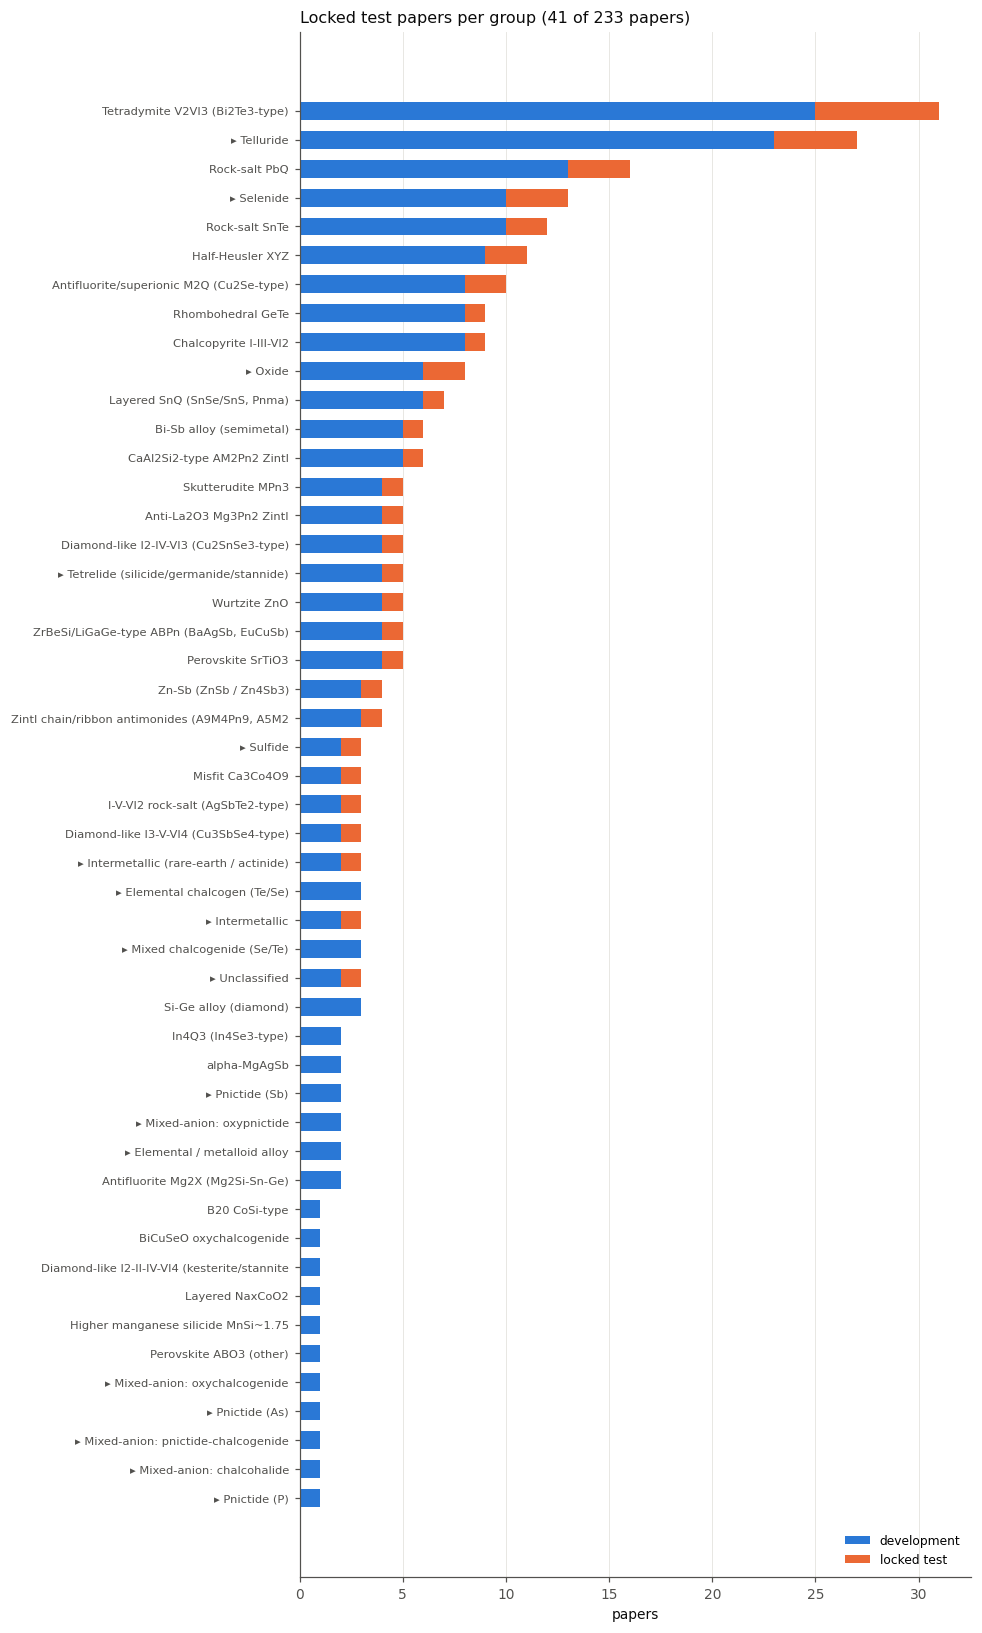

development folds (primary seed):


,points,papers
dev_fold_s42,,
0,1059,36
1,1060,39
2,1059,39
3,1059,39
4,1059,39


In [31]:
def h(x): return hashlib.sha256(x.encode()).hexdigest()
paper_stratum = d.groupby("SID")["group"].agg(lambda s: s.value_counts().idxmax())
test_sids = []
for g, sids in paper_stratum.groupby(paper_stratum):
    sids = sorted(sids.index, key=lambda s: h(f"{TEST_SALT}-{s}"))
    npap = len(sids)
    k = 0 if npap < 3 else max(int(round(TEST_FRACTION * npap)), 1 if npap >= 5 else 0)
    test_sids += sids[:k]
test_sids = sorted(int(s) for s in test_sids)
d["split"] = np.where(d["SID"].isin(test_sids), "test", "dev")
assert (d.groupby("SID")["split"].nunique() == 1).all()
split_tab = d.groupby("split").agg(points=("point_id", "size"), samples=("sample_key", "nunique"), papers=("SID", "nunique"))
split_tab["share_of_papers"] = (split_tab.papers / split_tab.papers.sum()).round(3)
display(split_tab)
by_g = (d.groupby(["group", "split"])["SID"].nunique().unstack(fill_value=0)
          .assign(total=lambda x: x.sum(axis=1)).sort_values("total", ascending=False))
display(by_g)

fig, ax = plt.subplots(figsize=(9, 0.28 * len(by_g) + 1.2))
y = np.arange(len(by_g))[::-1]
ax.barh(y, by_g["dev"], color=CAT[0], height=0.62, label="development")
ax.barh(y, by_g["test"], left=by_g["dev"], color=CAT[1], height=0.62, label="locked test")
ax.set_yticks(y, [g_.replace("[fallback] ", "▸ ")[:45] for g_ in by_g.index], fontsize=7.5)
ax.set_xlabel("papers"); ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title(f"Locked test papers per group ({split_tab.loc['test', 'papers']} of {split_tab.papers.sum()} papers)",
             loc="left", fontsize=10.5, color=INK)
plt.tight_layout(); plt.savefig(OUT / "fig_test_split.png"); plt.show()

# development folds: same method as before (hash order + greedy balance by points), rebuilt on dev papers only
def make_folds(df, n_folds, seed):
    pts = df.groupby("SID").size()
    key = {sid: h(f"{seed}-{sid}") for sid in pts.index}
    order = sorted(pts.index, key=lambda sid: (-pts[sid], key[sid]))
    load, fold_of = [0] * n_folds, {}
    for sid in order:
        k = min(range(n_folds), key=lambda i: (load[i], i)); fold_of[sid] = k; load[k] += pts[sid]
    return df["SID"].map(fold_of)

dev = d[d.split == "dev"].reset_index(drop=True)
for sd in SEEDS:
    dev[f"dev_fold_s{sd}"] = make_folds(dev, N_FOLDS, sd).to_numpy()
assert all((dev.groupby("SID")[f"dev_fold_s{sd}"].nunique() == 1).all() for sd in SEEDS)
print("development folds (primary seed):"); display(dev.groupby(f"dev_fold_s{SEEDS[0]}").agg(points=("point_id", "size"), papers=("SID", "nunique")))

## Physics helpers (SPB, N_c, fold-wise m*)

In [32]:
_eta = np.linspace(-30, 100, 2601)
_F = lambda j, e: quad(lambda x: x**j * expit(e - x), 0, max(e, 0) + 60, limit=200)[0]
_F12 = np.array([_F(0.5, e) for e in _eta]); _F1 = np.array([_F(1.0, e) for e in _eta]); _F0 = np.logaddexp(0, _eta)

def spb_seebeck_abs_uVK(n_m3, T_K, m_star=1.0):
    n_m3, T_K = np.asarray(n_m3, float), np.asarray(T_K, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        F12 = n_m3 / (4 * np.pi * (2 * m_star * M_E * KB * T_K / H_PL**2) ** 1.5)
        eta = np.interp(np.log(F12), np.log(_F12), _eta)
        lo, hi = F12 < _F12[0], F12 > _F12[-1]
        eta = np.where(lo, np.log(F12 * 2 / np.sqrt(np.pi)), eta)
        e_hi = (1.5 * F12) ** (2 / 3); e_hi = (1.5 * F12 / (1 + np.pi**2 / (8 * e_hi**2))) ** (2 / 3)
        eta = np.where(hi, e_hi, eta)
        S = np.where(lo, 2 - eta, np.where(hi, np.pi**2 / (3 * eta),
                     2 * np.interp(eta, _eta, _F1) / np.interp(eta, _eta, _F0) - eta))
    return S * KBE_UV

def N_c(T_K, m_star): return 2 * (2 * np.pi * np.asarray(m_star) * M_E * KB * np.asarray(T_K) / H_PL**2) ** 1.5

def fit_mstar(g):
    w = g["w"].to_numpy(); S, n, T = g["S_abs_uVK"].to_numpy(), g["n_m3"].to_numpy(), g["T_K"].to_numpy()
    loss = lambda lm: np.sum(w * np.abs(S - spb_seebeck_abs_uVK(n, T, np.exp(lm)))) / w.sum()
    return float(np.exp(minimize_scalar(loss, bounds=np.log(M_BOUNDS), method="bounded", options={"xatol": 1e-4}).x))

def fit_mstar_table(train):
    """family -> m* (families with >= MIN_TRAIN_PAPERS training papers) and the overall m*."""
    return {f: fit_mstar(g) for f, g in train.groupby("family") if g["SID"].nunique() >= MIN_TRAIN_PAPERS}, fit_mstar(train)

def add_dimensionless(df, fam, m_glob):
    df = df.copy()
    df["mstar"] = df["family"].map(fam).fillna(m_glob).to_numpy()
    df["s_SPB"] = spb_seebeck_abs_uVK(df["n_m3"], df["T_K"], df["mstar"]) / KBE_UV
    df["ln_n_Nc"] = np.log(df["n_m3"] / N_c(df["T_K"], df["mstar"]))
    df["y"] = df["s"] - df["s_SPB"]
    return df

def clean_train(df): return df[~df.bip] if TRAIN_EXCLUDE_BIPOLAR else df
def splits_from(col):
    col = np.asarray(col); return [(np.where(col != k)[0], np.where(col == k)[0]) for k in sorted(np.unique(col))]
def mae(a, b): return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
def r2(y, p): y, p = np.asarray(y, float), np.asarray(p, float); return float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2))

### Fold cache
For every seed × fold, m* is fitted once on the training papers (bipolar points removed) and the dimensionless columns are
built for train and test. All models below reuse the same frames, so comparisons are exactly paired.

In [21]:
t0 = time.time(); FOLDS = {}
for sd in SEEDS:
    for k, (tr, te) in enumerate(splits_from(dev[f"dev_fold_s{sd}"])):
        train_raw = clean_train(dev.iloc[tr])
        fam, mg = fit_mstar_table(train_raw)
        FOLDS[(sd, k)] = (add_dimensionless(train_raw, fam, mg), add_dimensionless(dev.iloc[te], fam, mg), te)
print(f"{len(FOLDS)} fold frames built ({time.time() - t0:.0f} s)")

def cv_predict(fit_predict):
    """fit_predict(train, test) -> predicted s for test. Returns {seed: out-of-fold array}."""
    out = {sd: np.full(len(dev), np.nan) for sd in SEEDS}
    for (sd, k), (train, test, te) in FOLDS.items():
        out[sd][te] = fit_predict(train, test)
    return out

def summarize(oof, name):
    rows = []
    for sd, p_ in oof.items():
        rows.append({"model": name, "seed": sd, "R2": r2(dev.s, p_), "MAE_uVK": mae(dev.s, p_) * KBE_UV,
                     "RMSE_uVK": rmse(dev.s, p_) * KBE_UV})
    return rows

25 fold frames built (9 s)


## Step 2: decide the inputs (development papers only)
Same seeds, folds and rows for both versions; s_SPB stays the **baseline** in both. The question is only whether the
correction model also needs s_SPB as an **input**.

In [22]:
def xgb_correction(inputs):
    def f(train, test):
        m = xgb.XGBRegressor(**XGB_PARAMS).fit(train[inputs], train.y, sample_weight=train.w)
        return test.s_SPB.to_numpy() + m.predict(test[inputs])
    return f

t0 = time.time(); dec_rows = []
for name, inp in CANDIDATE_SETS.items():
    dec_rows += summarize(cv_predict(xgb_correction(inp)), name)
    print(f"  {name} done ({time.time() - t0:.0f} s)")
dec_df = pd.DataFrame(dec_rows)
decision = []
for with_, without in PAIRS:
    a = dec_df[dec_df.model == with_].set_index("seed"); b = dec_df[dec_df.model == without].set_index("seed")
    dR2, dMAE = b.R2 - a.R2, b.MAE_uVK - a.MAE_uVK
    ok = (dR2.mean() > -R2_TOLERANCE) and (dMAE.mean() < 0.5)
    decision.append({"input set": with_.split(" | ")[0], "R² with s_SPB input": a.R2.mean(), "R² without": b.R2.mean(),
                     "ΔR² (without − with)": dR2.mean(), "ΔR² sd": dR2.std(), "ΔMAE µV/K": dMAE.mean(),
                     "seeds not worse": int((dR2 >= -1e-4).sum()), "decision": "drop s_SPB input" if ok else "keep s_SPB input",
                     "use": without if ok else with_})
decision = pd.DataFrame(decision).set_index("input set")
display(decision.round(4))
FINAL_SETS = {u.split(" | ")[0]: CANDIDATE_SETS[u] for u in decision["use"]}
print("FINAL input sets:", FINAL_SETS)

  Hall-only | s_SPB input done (12 s)
  Hall-only | no s_SPB input done (17 s)
  Hall + mob + val | s_SPB input done (25 s)
  Hall + mob + val | no s_SPB input done (31 s)


,R² with s_SPB input,R² without,ΔR² (without − with),ΔR² sd,ΔMAE µV/K,seeds not worse,decision,use
input set,,,,,,,,
Hall-only,0.5978,0.5964,-0.0013,0.0093,0.9517,3,keep s_SPB input,Hall-only | s_SPB input
Hall + mob + val,0.6740,0.6757,0.0018,0.0042,-0.1264,4,drop s_SPB input,Hall + mob + val | no s_SPB input


FINAL input sets: {'Hall-only': ['s_SPB', 'ln_n_Nc', 'tau'], 'Hall + mob + val': ['ln_n_Nc', 'tau', 'log10_mu', 'val_mean']}


## Step 4: the baseline ladder (development papers, all seeds × folds)
| Level | Model | Question it answers |
|---|---|---|
| 1 | SPB (family m*) | how far does physics alone get? |
| 2a | SPB + **linear** correction in the final inputs | does a straight-line fix already do it? |
| 2b | SPB + **quadratic** correction (all squares and pairwise products, tiny ridge) | does a simple curved fix do it? |
| 3 | SPB + PySR | *next notebook* |
| 4 | SPB + XGBoost correction | best black-box correction with the same inputs (upper benchmark) |
| 4′ | XGBoost direct (no baseline) | what a pure black box gets from the same inputs |

All corrections are trained with the per-sample weights, bipolar training points removed, and m* refitted per fold.

In [23]:
def linear_correction(inputs):
    def f(train, test):
        m = LinearRegression().fit(train[inputs], train.y, sample_weight=train.w)
        return test.s_SPB.to_numpy() + m.predict(test[inputs])
    return f

def quadratic_correction(inputs):
    def f(train, test):
        m = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), Ridge(alpha=QUAD_RIDGE_ALPHA))
        m.fit(train[inputs], train.y, ridge__sample_weight=train.w)
        return test.s_SPB.to_numpy() + m.predict(test[inputs])
    return f

def xgb_direct(inputs):
    inp = [c for c in inputs if c != "s_SPB"]
    def f(train, test):
        return xgb.XGBRegressor(**XGB_PARAMS).fit(train[inp], train.s, sample_weight=train.w).predict(test[inp])
    return f

t0 = time.time(); ladder_rows, LINEAR_COEFS = [], {}
spb_only = cv_predict(lambda tr, te: te.s_SPB.to_numpy())
for set_name, inp in FINAL_SETS.items():
    for level, name, fn in [("1", "SPB (family m*)", None), ("2a", "SPB + linear", linear_correction(inp)),
                            ("2b", "SPB + quadratic", quadratic_correction(inp)), ("4", "SPB + XGBoost", xgb_correction(inp)),
                            ("4′", "XGBoost direct", xgb_direct(inp))]:
        oof = spb_only if fn is None else cv_predict(fn)
        for r_ in summarize(oof, name):
            ladder_rows.append({**r_, "input set": set_name, "level": level})
    # interpretable coefficients of the linear correction, fitted on ALL development papers (for the thesis text)
    fam, mg = fit_mstar_table(clean_train(dev)); full_dev = add_dimensionless(clean_train(dev), fam, mg)
    lr = LinearRegression().fit(full_dev[inp], full_dev.y, sample_weight=full_dev.w)
    LINEAR_COEFS[set_name] = {"intercept": float(lr.intercept_), **{c: float(v) for c, v in zip(inp, lr.coef_)}}
    print(f"  {set_name} done ({time.time() - t0:.0f} s)")
ladder = pd.DataFrame(ladder_rows)
ladder_tab = (ladder.groupby(["input set", "level", "model"])[["R2", "MAE_uVK", "RMSE_uVK"]].agg(["mean", "std"]))
ladder_tab.columns = [f"{a}_{b}" for a, b in ladder_tab.columns]
display(ladder_tab.round(3))
print("Linear correction Δs = a + Σ b_i x_i fitted on all development papers:")
display(pd.DataFrame(LINEAR_COEFS).round(4))

  Hall-only done (12 s)
  Hall + mob + val done (26 s)


R2_mean  R2_std  MAE_uVK_mean  MAE_uVK_std  RMSE_uVK_mean  RMSE_uVK_std
input set        level model                                                                                   
Hall + mob + val 1     SPB (family m*)    0.355   0.019        66.373        1.252         95.807         1.414
                 2a    SPB + linear       0.617   0.008        51.879        1.017         73.817         0.772
                 2b    SPB + quadratic    0.659   0.017        48.733        1.297         69.616         1.711
                 4     SPB + XGBoost      0.676   0.006        47.830        0.775         67.929         0.658
                 4′    XGBoost direct     0.664   0.009        48.778        0.641         69.149         0.962
Hall-only        1     SPB (family m*)    0.355   0.019        66.373        1.252         95.807         1.414
                 2a    SPB + linear       0.616   0.013        52.139        1.208         73.956         1.287
                 2b    SPB + quadratic    0.619   0.012        51.440        1.196         73.595         1.197
                 4     SPB + XGBoost      0.598   0.007        52.863        0.555         75.657         0.682
                 4′    XGBoost direct     0.594   0.011        53.991        1.028         76.025         1.011

Linear correction Δs = a + Σ b_i x_i fitted on all development papers:


,Hall-only,Hall + mob + val
intercept,-0.0279,0.0691
s_SPB,-0.2682,NaN
ln_n_Nc,0.0670,0.1970
tau,0.4358,0.3657
log10_mu,NaN,-0.2375
val_mean,NaN,-0.0404


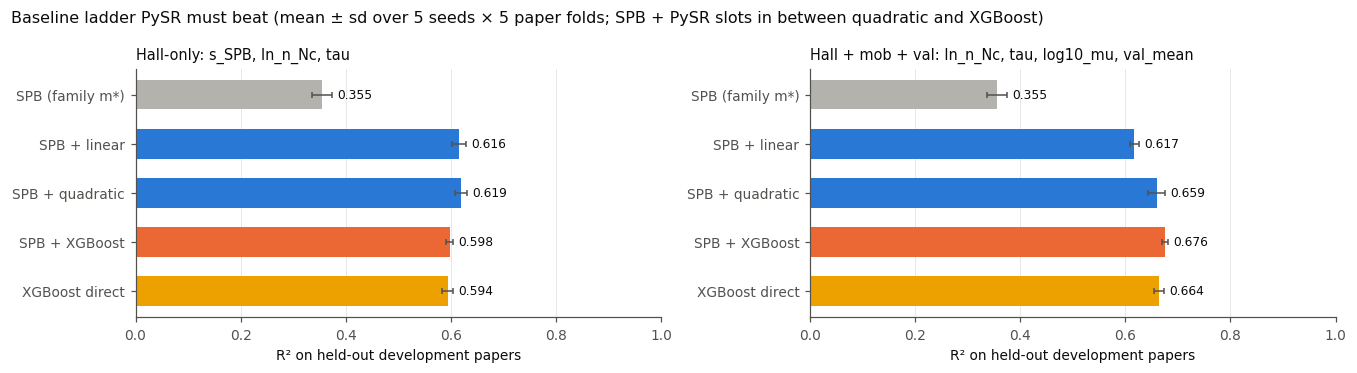

In [24]:
fig, ax = plt.subplots(1, len(FINAL_SETS), figsize=(6.2 * len(FINAL_SETS), 3.4), sharex=True, squeeze=False); ax = ax[0]
order = ["SPB (family m*)", "SPB + linear", "SPB + quadratic", "SPB + XGBoost", "XGBoost direct"]
colors = [NEUTRAL, CAT[0], CAT[0], CAT[1], CAT[3]]
for a, set_name in zip(ax, FINAL_SETS):
    t = ladder_tab.loc[set_name].reset_index().set_index("model").loc[order]
    y = np.arange(len(order))[::-1]
    a.barh(y, t.R2_mean, xerr=t.R2_std, color=colors, height=0.6, error_kw=dict(ecolor=INK2, lw=1, capsize=2))
    for yi, v, e in zip(y, t.R2_mean, t.R2_std):
        a.text(v + e + 0.01, yi, f"{v:.3f}", va="center", fontsize=8, color=INK)
    a.set_yticks(y, order); a.set_xlabel("R² on held-out development papers")
    a.set_title(f"{set_name}: {', '.join(FINAL_SETS[set_name])}", loc="left", fontsize=9.5, color=INK)
    a.xaxis.grid(True, color=GRID, lw=0.6); a.set_axisbelow(True); a.set_xlim(0, 1)
fig.suptitle("Baseline ladder PySR must beat (mean ± sd over 5 seeds × 5 paper folds; SPB + PySR slots in between quadratic and XGBoost)",
             x=0.01, ha="left", fontsize=10.5, color=INK)
plt.tight_layout(); plt.savefig(OUT / "fig_baseline_ladder.png"); plt.show()

## Step 3: freeze the dataset and the configuration
- `frozen_dataset.csv`: every row used (dev + test) with `split`, the development fold columns, the raw columns needed to
  recompute everything, and `mstar_devall` / `s_SPB_devall` / `ln_n_Nc_devall` / `y_devall`: m* fitted on **all development
  papers**. Those are the columns for the final fit, which is then scored once on the test papers.
- `frozen_config.json`: every setting, the test paper IDs, the chosen inputs, the baseline scores to beat, and file hashes.

**Rule for all later notebooks:** read these two files, never re-derive them; use only `split == "dev"` rows and the
  `dev_fold_s*` columns for any tuning; evaluate `split == "test"` exactly once, at the end.

In [25]:
fam_dev, mg_dev = fit_mstar_table(clean_train(dev))
fz = add_dimensionless(d, fam_dev, mg_dev).rename(columns={"mstar": "mstar_devall", "s_SPB": "s_SPB_devall",
                                                          "ln_n_Nc": "ln_n_Nc_devall", "y": "y_devall"})
for sd in SEEDS:
    fz[f"dev_fold_s{sd}"] = fz["point_id"].map(dev.set_index("point_id")[f"dev_fold_s{sd}"]).astype("Int64")
cols = (["point_id", "split", "study_id", "SID", "DOI", "sample_key", "sample_name", "composition", "host", "family", "broad_class",
         "class_level", "group", "carrier_type", "T_K", "n_m3", "log10_n_cm3", "log10_sigma_Sm", "el_n_valence_mean",
         "S_uVK", "S_abs_uVK", "flag_bipolar_post_peak", "w", "s", "tau", "log10_mu", "val_mean",
         "mstar_devall", "s_SPB_devall", "ln_n_Nc_devall", "y_devall"] + [f"dev_fold_s{sd}" for sd in SEEDS])
fz = fz[[c for c in cols if c in fz.columns]]
fz.to_csv(OUT / "frozen_dataset.csv", index=False)
DATA_SHA256 = hashlib.sha256((OUT / "frozen_dataset.csv").read_bytes()).hexdigest()

config = {
    "created": time.strftime("%Y-%m-%d %H:%M:%S"),
    "source_file": {"name": "features_with_folds.csv (m* calibration notebook)", "sha256": SOURCE_SHA256},
    "frozen_dataset": {"file": "frozen_dataset.csv", "sha256": DATA_SHA256, "rows": len(fz),
                       "dev_rows": int((fz.split == "dev").sum()), "test_rows": int((fz.split == "test").sum()),
                       "dev_papers": int(fz[fz.split == "dev"].SID.nunique()), "test_papers": int(fz[fz.split == "test"].SID.nunique())},
    "row_filters": {"exclude_families": EXCLUDE_FAMILIES, "T_min_K": T_MIN, "require_mobility": REQUIRE_MOBILITY,
                    "counts": steps},
    "target": {"quantity": "|S| (magnitude only; sign not modelled)", "dimensionless": "s = |S|/(k_B/e)",
               "k_B_over_e_uV_per_K": KBE_UV, "correction_target": "Δs = s − s_SPB (additive)"},
    "baseline": {"model": "single parabolic band, acoustic-phonon scattering, Hall factor 1",
                 "m_star": "one per family (>= %d training papers) else overall; fitted on TRAINING papers only, "
                           "loss = sample-weighted mean |S − S_SPB|, bounds %s m_e" % (MIN_TRAIN_PAPERS, list(M_BOUNDS)),
                 "mstar_devall": {**{k: round(v, 4) for k, v in fam_dev.items()}, "__overall__": round(mg_dev, 4)}},
    "features": {"s_SPB": "S_SPB/(k_B/e)", "ln_n_Nc": "ln(n / N_c), N_c = 2(2π m* k_B T/h²)^1.5 with the fold m*",
                 "tau": f"T / {T_REF} K", "log10_mu": "log10[σ/(n e)] in cm²/(V·s)", "val_mean": "mean valence electrons"},
    "input_decision": decision.round(5).reset_index().to_dict(orient="records"),
    "final_input_sets": FINAL_SETS,
    "training_rules": {"bipolar_post_peak_points": "removed from TRAINING only; test points always kept" if TRAIN_EXCLUDE_BIPOLAR else "kept",
                       "sample_weights": "1 / (points in the sample)", "m_star_refit": "inside every training fold"},
    "splits": {"test_selection": f"per-group strata; SHA-256('{TEST_SALT}-SID') order; fraction {TEST_FRACTION}",
               "test_SIDs": test_sids,
               "dev_folds": f"{N_FOLDS} folds per seed; order SHA-256('seed-SID'), greedy balance by points",
               "seeds": SEEDS, "primary_seed": SEEDS[0], "fold_columns": [f"dev_fold_s{sd}" for sd in SEEDS]},
    "baselines_to_beat_dev_cv": {k: {m_: {"R2_mean": round(r_.R2_mean, 4), "R2_sd": round(r_.R2_std, 4),
                                          "MAE_uVK_mean": round(r_.MAE_uVK_mean, 2), "RMSE_uVK_mean": round(r_.RMSE_uVK_mean, 2)}
                                     for (lv, m_), r_ in ladder_tab.loc[k].iterrows()} for k in FINAL_SETS},
    "linear_correction_coefficients_devall": LINEAR_COEFS,
    "model_settings": {"XGB_PARAMS": XGB_PARAMS, "quadratic_ridge_alpha": QUAD_RIDGE_ALPHA},
    "rules_for_later_notebooks": ["read frozen_dataset.csv and frozen_config.json; do not re-derive splits or filters",
                                  "tune only on split == 'dev' using dev_fold_s* columns, refitting m* inside each training fold",
                                  "evaluate split == 'test' exactly once, with m* fitted on all dev papers (the *_devall columns)"],
    "environment": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                    "sklearn": sklearn.__version__, "xgboost": xgb.__version__},
}
(OUT / "frozen_config.json").write_text(json.dumps(config, indent=2, default=float))
pd.Series(test_sids, name="SID").to_csv(OUT / "test_papers.csv", index=False)
decision.to_csv(OUT / "input_decision.csv"); ladder_tab.to_csv(OUT / "baseline_ladder_dev.csv"); ladder.to_csv(OUT / "baseline_ladder_per_seed.csv", index=False)
print(json.dumps(config["frozen_dataset"], indent=2))
print("final input sets:", FINAL_SETS)

{
  "file": "frozen_dataset.csv",
  "sha256": "c03b146df0ce4cc142d90a930bca11deb38b330dbe0992d838f78626acb617c0",
  "rows": 6415,
  "dev_rows": 5296,
  "test_rows": 1119,
  "dev_papers": 192,
  "test_papers": 41
}
final input sets: {'Hall-only': ['s_SPB', 'ln_n_Nc', 'tau'], 'Hall + mob + val': ['ln_n_Nc', 'tau', 'log10_mu', 'val_mean']}


## Step 5 (optional): which family labels to check first
Labels that carry the most development data, or come from the least certain rules, matter most for m*. This list ranks
compositions for manual checking. Fill `verified_host` / `verified_family`, save the rows as `verified_hosts.csv`, rerun the m*
notebook with it, then **rerun this notebook**: changing labels changes m*, so the setup must be re-frozen. The test papers
stay the same, because they are chosen by hash.

In [26]:
rev = (dev.groupby("composition").agg(host=("host", "first"), family=("family", "first"), broad_class=("broad_class", "first"),
                                      class_level=("class_level", "first"), points=("point_id", "size"),
                                      samples=("sample_key", "nunique"), papers=("SID", "nunique")).reset_index())
uncert = {"L3 broad_fallback": 3, "L2 constrained_formula (composite)": 2, "L2 constrained_formula": 1, "L4 unclassified": 3}
rev["label_uncertainty"] = rev["class_level"].map(uncert).fillna(1)
rev["priority"] = rev["points"] * rev["label_uncertainty"]
rev = rev.sort_values("priority", ascending=False)
rev["verified_host"] = ""; rev["verified_family"] = ""
rev.to_csv(OUT / "family_review_priority.csv", index=False)
print("top of the review list (the full list is in family_review_priority.csv):"); display(rev.head(25))

top of the review list (the full list is in family_review_priority.csv):


,composition,host,family,broad_class,class_level,points,samples,papers,label_uncertainty,priority,verified_host,verified_family
602,W0.96Nb0.04Se1.7S0.3,None,None,Selenide,L3 broad_fallback,29,1,1,3,87,,
384,LaFeAsO0.89F0.11,None,None,Mixed-anion: oxypnictide,L3 broad_fallback,28,1,1,3,84,,
196,Bi85Sb15,Bi-Sb,Bi-Sb alloy (semimetal),Elemental / metalloid alloy,L2 constrained_formula,82,2,2,1,82,,
601,W0.94Nb0.06Se1.7S0.3,None,None,Selenide,L3 broad_fallback,26,1,1,3,78,,
144,Bi0.5Sb1.5Te3.0,Sb2Te3,Tetradymite V2VI3 (Bi2Te3-type),Telluride,L2 constrained_formula,71,4,1,1,71,,
222,Ce2PdSi3,None,None,Tetrelide (silicide/germanide/stannide),L3 broad_fallback,23,1,1,3,69,,
566,Sr2IrO4,None,None,Oxide,L3 broad_fallback,23,1,1,3,69,,
153,Bi0.88Sb0.12Ho0.01,None,None,Intermetallic,L3 broad_fallback,22,1,1,3,66,,
116,AgPb22.5SbTe20,None,None,Telluride,L3 broad_fallback,22,3,1,3,66,,
589,Th3As4,None,None,Pnictide (As),L3 broad_fallback,21,4,1,3,63,,


In [27]:
import shutil
shutil.make_archive("frozen_setup", "zip", OUT)
try:
    from google.colab import files
    files.download("frozen_setup.zip")
except ImportError:
    print("zip at frozen_setup.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>